# PTM3D tutorial 04 — (101955) Bennu on a real ephemeris

The same generic-body path as [tutorial 03](03_asteroid_thermal.ipynb), with the
analytic orbit replaced by a real SPICE ephemeris and the synthetic icosphere
replaced by a real facet shape model. The body is (101955) Bennu, the
OSIRIS-REx sample-return target.

Tutorial 03's two-body propagation is exact for an isolated Sun-asteroid pair
with fixed osculating elements. A SPICE ephemeris carries a fitted or integrated
trajectory instead — an orbit determination that has already absorbed planetary
perturbations, or, for a spacecraft target, radiometric tracking. Use it when a
result has to match a real calendar date, a real distance and phase angle, or
real mission geometry. Section 6 measures how much difference that makes for
Bennu, on this engine, with no external orbital mechanics.

**Cost:** four CPU-only runs on the 49,152-facet OSIRIS-REx shape model, two
rotations of output after roughly 40 rotations of spin-up: about 33 minutes in
total on four cores.

**Needs:** the `ptm` package, a built `ptm_thermal_sim`, and
`scripts/fetch_kernels.py --bodies bennu` — which fetches both the shared
generic SPICE kernels and Bennu's own ephemeris. Bennu's meta-kernel and both
of its shape models ship in the repository; its ephemeris does not (80.7 MB).
Section 3
documents where each came from and how to source the equivalent for another
body.


In [1]:
from ptm import paths, run as engine

CONFIG = "examples/quickstart_asteroid_bennu.yaml"
BODY = "data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)"
pre = paths.preflight([CONFIG, "data/kernels/bennu.tm", "data/kernels/lsk/naif0012.tls",
                       "data/kernels/spk/de440s.bsp", f"{BODY}/ephemeris.spk",
                       f"{BODY}/bennu_radar_shape.obj"], engine="ptm_thermal_sim")
print(pre)
pre.raise_if_missing()

found    <repo>/build/bin/ptm_thermal_sim
found    examples/quickstart_asteroid_bennu.yaml
found    data/kernels/bennu.tm
found    data/kernels/lsk/naif0012.tls
found    data/kernels/spk/de440s.bsp
found    data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/ephemeris.spk
found    data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/bennu_radar_shape.obj

Repo root: <repo>
Engine:    <repo>/build/bin/ptm_thermal_sim


<Report 7/7 found>

## 1. Run it, at Bennu's 2019-01-10 perihelion

`ephemeris.spk` covers 2014-12-31 to 2023-05-30. Scanning that window one sample
per day puts the perihelion nearest the middle of OSIRIS-REx proximity
operations at 2019-01-10, r = 0.897 AU — found from the file this run also
loads, not assumed from a catalog. Section 5 uses the matching aphelion.

In [2]:
perihelion = engine.run_engine(pre.root / CONFIG, echo=True)
peri = perihelion.results(body_radius_km=0.2447)

Running: <repo>/build/bin/ptm_thermal_sim --config <repo>/examples/quickstart_asteroid_bennu.yaml
(cwd=<repo>)



╔═══════════════════════════════════════════════════════════════╗
║    *      .    *     \   ||    //      * .   .      *         ║
║       .      *     \  \  ||   //    //       .             .  ║
║  *      .       \   \  \  ☀  //    //      .      *           ║
║     .         *  \   ...-'''''-...//    *         .           ║
║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
║  ═══════════════════════════════════════════════════════════  ║
║      Coupled Thermal-Illumination for Planetary Bodies        ║
╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: <repo>/examples/quickstart_asteroid_bennu.yaml
✓ Configuration loaded from: <repo>/examples/quickstart_asteroid_bennu.yaml
Generic body custom mesh: data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/g_06370mm_alt_obj_0000n00000_v021.obj
Using generic body: 101955 Bennu (1999 RQ36)
Semi-major axis:

Loaded SPICE meta-kernel: <repo>/data/kernels/bennu.tm
========== Thermal Equilibration Configuration ==========
Body: 101955 Bennu (1999 RQ36)
Synodic day (solar day): 0.18 Earth days
Equilibration (configured): 40.00 day/night cycles  (thermal.equilibration_orbits)
Equilibration (integrated): 40.00 day/night cycles = 1 pass(es) x 40.00-cycle forcing block  [default]
Seed surface anchor: lumped  (cycle-mean lumped-substrate anchor; the run's per-face census and its QUADRATURE are printed by the solver)
Spin-up seed: physical  (shared per-face conductive steady profile, identical on every solver path)
Equilibration (analytic seed, CPU paths only): 0 day/night cycles  (OFF -- spin-up is the configured equilibration under the REAL forcing)
Total equilibration period: 7.17 Earth days
Output window (for export): 0.36 Earth days
Requested integration (stats): 0.36 days with offset 0.00 days
Post-equilibration simulated span: 0.36 Earth days
Total simulation time: 7.52 Earth days
Time step c

[ephemeris] SPK coverage for 2101955 (NAIF 2101955, 1 kernel(s), 1 interval(s)): 1899-12-31T23:59:19 .. 2135-09-30T23:58:51 -- contains the run window 2019-01-02T20:01:53 .. 2019-01-10T08:33:01.
Running illumination simulation for 7.52 days (including 7.17 days equilibration) starting at 2019-01-02T20:01:53
[Embree] 4.3.3  traversal kernels: SSE (4-wide)  (native packets 4=yes 8=no 16=no)
[Embree] WARNING: this CPU has AVX but this Embree has no AVX kernels.
Ray traversal is running SSE2 BVH4 and is ~83 % of the
illumination phase. A multi-ISA build of the SAME Embree
version measured -7.0 % on the illumination phase of this
project's calib120 arm (18 paired repeats, 18/18 same sign,
2026-08-15). This is the Homebrew embree default.
Speed only -- but NOT result-neutral: on a lunar polar DEM
patch the ISA swap moved 75 of 260 output files, worst
face-frame |dT| 0.0091 K, because grazing occlusion verdicts
differ between ISA kernels. See INSTALL.md,
"Embree ISA (performance)".
[Illuminat

Initialized chunked storage with 1 chunks of up to 1000000 faces each


Calculating illumination:  [>                                                 ] 0% | elapsed 0s


... (25 outputs left out)

Progress 192/192
Export complete: 192/192
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_asteroid_bennu
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
Face count: 49152
Time steps: 192
Computing illumination statistics...
Computing direct solar statistics...
Computing primary reflected statistics...
Computing primary IR statistics...


Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_asteroid_bennu/statistics
[albedo] effective surface albedo (flux-weighted over the DIRECT beam, the value the BC absorbed with): global A_eff = 0.017 over 49142/49152 ever-lit faces; per-face -> output/quickstart_asteroid_bennu/statistics/effective_albedo.bin (uint32 n + float32[49152], NaN where never lit).
Reduced over the INTEGRATION window, abs steps [1921,2113) -- the same window as every other statistics/*.bin, so a closure audit may divide the two directly.
[kirchhoff] absorb == emit == scatter: eps = 0.95 (IR albedo 0.05) at cpu_array=0.94999999999999996, emit=0.95, radiosity=n/a (radiation off)
Simulation completed in 486.093 seconds (486093 ms)
Results:
Average total flux: 807.918244354 W/m^2
- Direct solar: 807.918244354 W/m^2
- Primary reflected: 0.000000000 W/m^2
- Primary IR: 0.000000000 W/m^2
Maximum total flux: 1693.254599375

Memory cleanup completed.
Cleaning up remaining memory...
Cleanup completed successfully



--- 489 output lines; 487.2 s wall; exit code 0 ---


## 2. The first look

`plot_shape` draws the run's own facets. `plot_globes`, used in the other
notebooks, normalizes the vertices onto a sphere — right for an icosphere and
wrong for a spinning top.

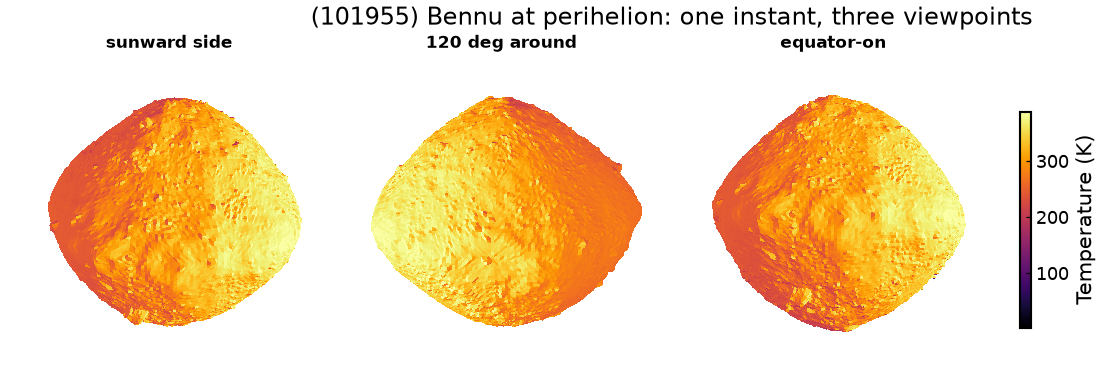

In [3]:
VIEWS = [(20, 155, "sunward side"), (20, 275, "120 deg around"), (0, 155, "equator-on")]
fig = peri.plot_shape(step=144, views=VIEWS, figsize=(12.6, 3.8),
                      suptitle="(101955) Bennu at perihelion: one instant, three viewpoints")
for panel in fig.axes[:len(VIEWS)]:
    panel.set_box_aspect((1, 1, 1), zoom=1.4)   # fill the panel with the body

Bennu's equatorial ridge and flattened poles are the shape's real contribution
to the temperature field. On tutorial 03's sphere every facet at a given
latitude saw identical geometry; here each facet's own tilt toward the Sun and
toward its neighbors varies with position, so the same diurnal cycle arrives
modulated by per-facet slope and local horizon shadowing. The terminator is
visibly ragged for that reason.

## 3. Where the data came from

A real body needs three tiers of data, all under `data/`: the shared generic
kernels every body uses; a per-body meta-kernel; and the body's own ephemeris
and shape. The shape is sourced by hand, and this section is the record of how.
The ephemeris is fetched by `scripts/fetch_kernels.py --bodies bennu`: JPL
solution 118 (1900 to 2135), a later solution than the archived solution 76
that the SPICE cells below inspect (the two differ by at most 13.9 km on this
window, worth about 2e-4 K).

### Shape: DAMIT first, PDS Small Bodies Node as the fallback

`damit.DAMITClient` searches [DAMIT](https://damit.cuni.cz/), the database of
asteroid models from lightcurve inversion. Bennu's shape models are not
lightcurve-inversion products — they come from radar delay-Doppler imaging and,
post-encounter, from OSIRIS-REx laser altimetry — so this is a real check rather
than a rhetorical one.

In [4]:
from damit import DAMITClient

damit = DAMITClient()
for query in ("Bennu", "101955"):
    print(f"DAMIT search({query!r}) -> {len(damit.search_asteroid(query))} match(es)")

DAMIT search('Bennu') -> 0 match(es)


DAMIT search('101955') -> 0 match(es)


No match, so the shape models come from the PDS Small Bodies Node. The
sourcing record below is for the pre-encounter radar model:
[PDS SBN, shape model of asteroid (101955) Bennu](https://sbn.psi.edu/pds/resource/bennushape.html),
`urn:nasa:pds:ast-bennu.radar.shape-model::1.1` — Nolan, M. C. et al. (2013),
*Shape model and surface properties of the OSIRIS-REx target asteroid (101955)
Bennu from radar and lightcurve observations*, Icarus 226, 629-640,
[doi:10.1016/j.icarus.2013.05.028](https://doi.org/10.1016/j.icarus.2013.05.028).
NASA PDS archival data, public domain; cite the paper on reuse.

The bundle's `data/101955bennu.tab` uses the same `v x y z` / `f i j k` format
DAMIT shape files use, and `damit.shape_converter` reads either unmodified. The
pole (ecliptic $\lambda = 45^\circ$, $\beta = -88^\circ$) and rotation period
(4.29746 h, Hergenrother et al. 2013) ship in the same bundle and are what
`generic_body.spin` uses, converted to equatorial coordinates by the same
formula `DAMITSpinParams` applies to a real DAMIT model. The converted file
carries the citation in its own header.

The engine runs in this notebook use the later OSIRIS-REx laser-altimeter model,
`g_06370mm_alt_obj_0000n00000_v021.obj` (OLA v21, 6.37 m sampling, 49,152
facets), shipped beside it in the same directory. Its provenance and checksums
are in `data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/PROVENANCE.md`.


In [5]:
shape = pre.root / BODY / "bennu_radar_shape.obj"
print("\n".join(l for l in shape.read_text().splitlines() if l.startswith("#")))

# Wavefront OBJ shape model -- asteroid (101955) Bennu
#
# Source: Nolan, M.C., Magri, C., Howell, E.S., Benner, L.A.M., Giorgini, J.D.,
#   Hergenrother, C.W., Hudson, R.S., Lauretta, D.S., Margot, J.L., Ostro, S.J.,
#   Scheeres, D.J. (2013). Shape model and surface properties of the OSIRIS-REx
#   target asteroid (101955) Bennu from radar and lightcurve observations.
#   Icarus 226, 629-640. doi:10.1016/j.icarus.2013.05.028
# Archive: PDS Small Bodies Node, urn:nasa:pds:ast-bennu.radar.shape-model::1.1
#   https://sbnarchive.psi.edu/pds4/non_mission/ast-bennu.radar.shape-model_V1_1.zip
#   NASA PDS archival data; public domain / freely redistributable with citation.
# Converted from the archive's native "v x y z / f i j k" vertex-facet table
# (data/101955bennu.tab) verbatim -- vertices already in km, center of mass
# origin, principal-axis frame, z = spin (long) axis. 1348 vertices, 2692
# facets, ~25 m vertex spacing. No decimation applied (already small).
#


### Ephemeris: an archived mission SPK, not an on-demand one

JPL Horizons can generate a small-body SPK on request —
`horizons.HorizonsClient.download_spk` does exactly that for the
`269_Justitia`, `623_Chimaera` and `13294_Rockox` bodies already cached in this
repository — but not for Bennu:

```
COMMAND='101955', EPHEM_TYPE=SPK, CENTER='500@0' ->
"SPK creation is not available for pre-computed objects in the major body index"
```

Horizons declines ad hoc SPK generation for a handful of small bodies with
spacecraft-quality tracking. The right substitute is the mission's own archived
kernel: `bennu_refdrmc_v1.bsp` from the
[OSIRIS-REx SPICE archive](https://naif.jpl.nasa.gov/pub/naif/pds/pds4/orex/orex_spice/spice_kernels/spk/bennu_refdrmc_v1.bsp)
at the NAIF PDS4 node, "ephemerides of asteroid (101955) Bennu, created by the
OSIRIS-REx science team" — which is a better source anyway, being the trajectory
solution the mission flew against.

Read the body id the SPK declares rather than computing one from the asteroid
number: Horizons has migrated small-body ids between a `2000000+N` and a
`20000000+N` scheme, and a computed id can be wrong.

In [6]:
import spiceypy as sp

sp.furnsh(str(pre.root / "data/kernels/lsk/naif0012.tls"))
sp.furnsh(str(pre.root / BODY / "ephemeris.spk"))
start, end = sp.spkcov(str(pre.root / BODY / "ephemeris.spk"), 2101955)
print(f"SPK declares target 2101955, covering {sp.et2utc(start, 'C', 0)} "
      f"to {sp.et2utc(end, 'C', 0)}")
sp.kclear()

SPK declares target 2101955, covering 2014 DEC 31 23:58:53 to 2023 MAY 30 23:58:51


### Meta-kernel: how the path resolves

`generic_body.spice_metakernel` is resolved like this:

- an **absolute** path is used exactly as given;
- a **relative** path is looked for under the kernel directory first
  (`data/kernels/` unless `$PTM_SPICE_KERNELS` or the CMake cache variable
  `SPICE_KERNELS_DIR` says otherwise), then under the current working
  directory.

`data/kernels/bennu.tm` uses the bare-filename form, the same one `moon.tm`,
`europa.tm` and `mercury.tm` use. Its own `PATH_VALUES` then points back at the
body directory for `ephemeris.spk`. Every run prints the file it actually
loaded (`Loaded SPICE meta-kernel: ...`); if nothing resolves, the run stops
and lists every path it tried, rather than substituting another body's
metakernel.

## 4. The config, against tutorial 03's

| | 03, Keplerian | 04, SPICE |
|---|---|---|
| `generic_body.ephemeris_source` | `keplerian` | `spice` |
| Sun-body vector | analytic two-body propagation of `orbit:` | `spkpos_c` against `ephemeris.spk`, light-time and stellar-aberration corrected |
| `spice_metakernel` / `naif_id` | absent | required |
| `orbit:` block | the position source | present, but a fallback used only outside the SPK's coverage |
| `shape.type` | `spherical`, radius only | `custom_mesh`, a real facet model |
| `spin` pole | arbitrary teaching values | Bennu's real pole, about 178 deg obliquity — a fast retrograde rotator |
| external data | none beyond leapseconds | shared kernels, one body SPK, one shape file |

In [7]:
print((pre.root / CONFIG).read_text())

# PTM3D quickstart: asteroid (101955) Bennu on its real SPICE ephemeris, with
# the OSIRIS-REx mission shape model, near the 2019-01-10 perihelion of
# its orbit during the OSIRIS-REx proximity-operations era.
#
# Notebook counterpart of examples/quickstart_asteroid_diurnal.yaml (tutorial
# 03, Keplerian orbit, fictional body). This config is that notebook's SPICE
# counterpart: same generic-body thermal path, but the Sun-body vector comes
# from a real ephemeris file instead of an analytic two-body propagation, and
# the shape is Bennu's actual measured facet model instead of a sphere.
# See docs/tutorials/notebooks/04_asteroid_spice.ipynb for the full walkthrough.
#
# CPU-only and laptop-friendly, on a 49,152-facet mesh.
#
# Run FROM THE REPOSITORY ROOT:
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_asteroid_bennu.yaml
#
# ---------------------------------------------------------------------------
# Shape: data/horizons_cache/bodies/101955_Bennu_(1999_RQ36)/
# g_0637

As in tutorial 03, only `generic_body.surface:` is read for a generic body's
thermophysical properties. The values are Bennu's, not arbitrary:

- **Albedo 0.017**, the bolometric Bond albedo from the OCAMS phase curve
  (Golish et al. 2021). Bennu's *geometric* albedo is 0.044 — a very dark,
  B-type surface.
- **Thermal inertia** $\Gamma = \sqrt{0.075 \times 1500 \times 800} = 300$ SI,
  the OTES-derived global value (Rozitis et al. 2020), locally 200-700 over
  boulders and fines. The density and heat capacity reuse tutorial 03's regolith
  values for continuity, not as measurements: Bennu's *bulk* density of about
  1190 kg/m³ is a whole-body rubble-pile number, not a surface-layer grain
  density.
- **Spin** period 4.29746 h, pole at ecliptic (45, -88) deg, equatorial
  (86.64, -65.11) deg.

The run banner confirms which path engaged, which meta-kernel loaded, and the
NAIF id it resolved.

In [8]:
banner = perihelion.lines.index(
    next(l for l in perihelion.lines if l.startswith("Using generic body")))
print("\n".join(perihelion.lines[banner:banner + 12]))

Using generic body: 101955 Bennu (1999 RQ36)
Semi-major axis: 1.12892 AU
Eccentricity: 0.204651
Spin period: 4.29746 hours
Orbit epoch: JD 2451545 TDB  (mean anomaly 36.23987194 deg at this epoch)
Spin epoch:  JD 2451545 TDB  (prime meridian W0 = 0 deg at this epoch)
Solar constant: 1067.9 W/m^2
Synodic day: 4.29922 hours
Albedo: 0.017
Emissivity: 0.95
Body radius: 0.2437 km
Ephemeris: SPICE


One banner line needs a caveat. `Solar constant` is evaluated at the config's
fixed `orbit.semi_major_axis_au`, not at the instantaneous SPICE distance: it is
printed once at startup from the Keplerian *fallback* block and is the same
number whether the run is at perihelion or at aphelion. The real per-epoch
geometry is in `body_positions.csv`, whose Sun vector comes from
`ephemeris.spk` at every timestep, and that is what the rest of the notebook
reads.

## 5. Perihelion against aphelion

Bennu's orbit ($a = 1.129$ AU, $e = 0.205$) swings its solar flux by more than a
factor of two around the year. Scanning the SPK forward from the perihelion
above finds the matching aphelion 218 days later, on 2019-08-16. The second run
is the same config with two command-line overrides — no edited copy of the
config is needed.

In [9]:
import numpy as np

AU_KM = 1.495978707e8


def solar_distance_au(res):
    # Mean Sun-body distance over the output window, from body_positions.csv.
    p = res.body_positions()
    xyz = np.column_stack([p[f"sun_{a}"] for a in "xyz"])
    return float(np.linalg.norm(xyz, axis=1).mean() / AU_KM)


aph = engine.run_engine(pre.root / CONFIG, show=("Simulation completed in",),
                        extra_args=["--start", "2019-08-16T00:00:00", "--output",
                                    "output/quickstart_asteroid_bennu_aphelion"]
                        ).results(body_radius_km=0.2447)
r_peri, r_aph = solar_distance_au(peri), solar_distance_au(aph)
print(f"perihelion r = {r_peri:.4f} AU, aphelion r = {r_aph:.4f} AU, "
      f"insolation ratio {(r_aph / r_peri) ** 2:.2f}")

    Simulation completed in 486.000 seconds (486000 ms)
perihelion r = 0.8965 AU, aphelion r = 1.3553 AU, insolation ratio 2.29


perihelion : 8557 equatorial facets, mean 296.7 K, amplitude 139.2 K, peak at 13.25 h


aphelion   : 8557 equatorial facets, mean 246.4 K, amplitude 81.5 K, peak at 13.75 h


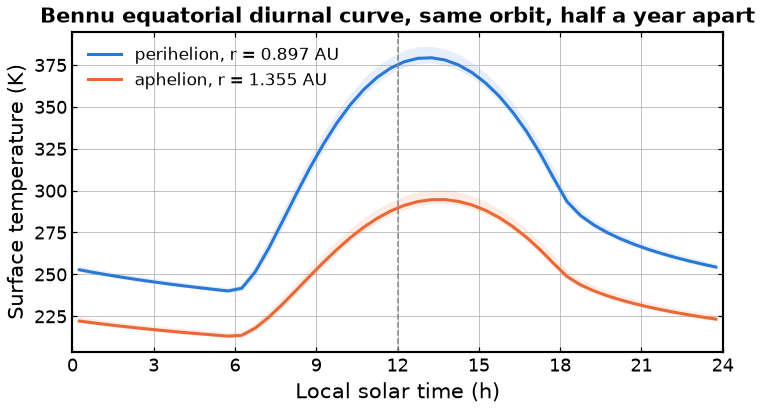

In [10]:
from ptm import plots

plt = plots.styled()
fig, ax = plt.subplots(figsize=(7, 4.0))
for res, r_au, color, label in ((peri, r_peri, "#2a78d6", "perihelion"),
                                (aph, r_aph, "#eb6834", "aphelion")):
    steps = res.steps("temperature")
    lst, T, lo, hi, n_faces = res.local_solar_time_curve(steps=steps[len(steps) // 2:])
    ax.plot(lst, T, color=color, lw=2, label=f"{label}, r = {r_au:.3f} AU")
    ax.fill_between(lst, lo, hi, color=color, alpha=0.12, linewidth=0)
    print(f"{label:11s}: {n_faces} equatorial facets, mean {T.mean():.1f} K, "
          f"amplitude {T.max() - T.min():.1f} K, peak at {lst[np.argmax(T)]:.2f} h")
ax.axvline(12, color="#898781", lw=1, ls="--")
ax.set_xlabel("Local solar time (h)")
ax.set_ylabel("Surface temperature (K)")
ax.set_title("Bennu equatorial diurnal curve, same orbit, half a year apart")
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False)
ax.grid(True, linewidth=0.5)
fig.tight_layout()

The mean equatorial temperature follows the fourth-root law almost exactly:
296.7 K against 246.4 K is a ratio of 1.20, and $2.29^{1/4} = 1.23$. The
diurnal amplitude does not — it falls by 41%, far more than the fourth root —
and the peak slips half an hour later. Both are the thermal parameter at work:
$\Theta \propto \Gamma\sqrt{\omega}/(\varepsilon\sigma T_{eq}^3)$ grows as
$r^{3/2}$ as the body cools, so the same surface behaves like a
higher-inertia one when it is farther from the Sun. Tutorial 03's figure raised
$\Gamma$ at fixed distance; this one raises the distance at fixed $\Gamma$, and
the curve responds the same way.

The inter-facet spread (shaded) is far wider than tutorial 03's, and that is
the shape: at fixed local solar time, facets on a rubble pile do not all see the
same geometry.

## 6. Why mission work needs ephemerides

Tutorial 03's propagator uses fixed osculating elements from one reference
epoch. Over a handful of orbits that is nearly exact; over years, unmodeled
perturbations — chiefly Earth and Jupiter, for a near-Earth asteroid — let the
real position drift from what those elements alone predict. Bennu's config
carries its own osculating elements, fit at J2000.0, in the Keplerian *fallback*
block. Running the same config with `ephemeris_source: keplerian` at the same
calendar date isolates the drift directly.

In [11]:
import yaml

kep_config = yaml.safe_load((pre.root / CONFIG).read_text())
kep_config["generic_body"]["ephemeris_source"] = "keplerian"
kep_config["output"]["directory"] = "output/_bennu_keplerian_check"
kep_path = pre.root / "output" / "_bennu_keplerian_check.yaml"
kep_path.parent.mkdir(exist_ok=True)
kep_path.write_text(yaml.safe_dump(kep_config, sort_keys=False))

kep = engine.run_engine(kep_path, show=("Simulation completed in",)
                        ).results(body_radius_km=0.2447)
r_kep = solar_distance_au(kep)
print(f"2019-01-10, identical shape, spin and thermal properties; only the "
      f"position source differs.\n"
      f"  SPICE ephemeris    : r = {r_peri:.4f} AU\n"
      f"  Keplerian fallback : r = {r_kep:.4f} AU\n"
      f"  difference         : {(r_kep - r_peri) * AU_KM:,.0f} km, "
      f"{100 * (r_kep - r_peri) / r_peri:.2f}% in distance, "
      f"{100 * (1 - (r_peri / r_kep) ** 2):.1f}% in insolation")

    Simulation completed in 476.312 seconds (476312 ms)
2019-01-10, identical shape, spin and thermal properties; only the position source differs.
  SPICE ephemeris    : r = 0.8965 AU
  Keplerian fallback : r = 0.9088 AU
  difference         : 1,829,182 km, 1.36% in distance, 2.7% in insolation


Nineteen years after the osculating epoch the two-body propagation is off by
over a million kilometers — a percent or so in distance, a couple of percent in
insolation. That is small in relative terms and exactly the scale that matters
for real work: a proximity-operations targeting solution, a phase-angle
photometric correction, or a light-time-corrected communication window all need
position accuracy well inside that band, at a specific UTC the mission actually
flies rather than "some point on the right orbit". The `LT+S` correction in the
SPICE path — light time plus stellar aberration — is the same kind of detail,
and it is why a navigation team's own trajectory file is the right source for
this class of problem.

It is worth being precise about what the error is and is not. The thermal model
is identical between the two arms and the drift enters only through the Sun-body
distance, so at 1.4% it is a flux error rather than a shape error. Section 5's
aphelion arm — a 51% change in distance — shows what a genuinely large one does
to the curve.

## 7. How much does the measured thermal inertia matter?

Every number in `generic_body.surface:` is live on this path — `albedo`,
`emissivity`, `ks`, `kd`, `rhos`, `rhod`, `cp0`, `H`, `Qb`, `chi` — and
[tutorial 03, section 4](03_asteroid_thermal.ipynb) covers the mechanics of
changing one and confirming it reached the solver. What this notebook can add
is that Bennu's values are *measurements*, and measurements have ranges. OTES
gives a global $\Gamma = 300$ SI, the value the config carries, with local
values from about 200 over fine-grained material to 700 over boulders (Rozitis
et al. 2020). The run below asks what that range is worth in kelvin.

At fixed $\rho_s c_p$, $\Gamma \propto \sqrt{k_s}$, so 700 SI is
$k_s = k_d = \Gamma^2 / (\rho_s c_p) = 0.408$ W/m/K. `derived=` keeps `kd`
locked to `ks`, which is what makes the column homogeneous and $\Gamma$ one
number rather than two.

In [12]:
import hashlib

from ptm import Sweep

boulder = Sweep(pre.root / CONFIG,
                grid={"generic_body.surface.ks": [700.0 ** 2 / (1500.0 * 800.0)]},
                derived={"generic_body.surface.kd":
                         lambda params: params["generic_body.surface.ks"]},
                outdir=pre.root / "output/bennu_boulder_inertia",
                results_kwargs={"body_radius_km": 0.2447})
boulder.run()

for label, res in (("300 SI (OTES global)", peri),
                   ("700 SI (boulder end)", boulder.points[0].results)):
    steps = res.steps("temperature")
    lst, T, lo, hi, n_faces = res.local_solar_time_curve(steps=steps[len(steps) // 2:])
    digest = hashlib.md5(
        (res.path / "statistics" / "temperature_max.bin").read_bytes()).hexdigest()
    print(f"{label}: mean {T.mean():6.1f} K, amplitude {T.max() - T.min():6.1f} K, "
          f"peak at {lst[np.argmax(T)]:5.2f} h, {digest[:8]}")

[sweep] engine <repo>/build/bin/ptm_thermal_sim (md5 2fbb9c16c1e7a8c4272dc1814a1b6544)
[sweep] axis generic_body.surface.ks: 1 values -> config key generic_body.surface.ks
[sweep] derived: generic_body.surface.kd (from the caller's own relation)


[sweep] ok   ks-0p408333 (487.7 s)
[sweep] 1 complete, 0 failed, 0 skipped, 487.7 s


300 SI (OTES global): mean  296.7 K, amplitude  139.2 K, peak at 13.25 h, 3dfda754


700 SI (boulder end): mean  304.7 K, amplitude   86.8 K, peak at 13.75 h, d1b573e1


Across the measured range the equatorial diurnal amplitude falls from 139.2 K
to 86.8 K, a 38% change, while the mean rises 8.0 K and the peak slips half an
hour later. Two things follow.

The first is that a thermal model of Bennu is only as sharp as its thermal
inertia: quoting a daytime temperature to a few kelvin means pinning $\Gamma$ to
much better than the boulder-to-fines range, which is why OTES resolved it per
region rather than globally. The second is the same statement read backwards,
and it is how $\Gamma$ gets measured in the first place — the curve shape is a
strong function of the property, so an observed curve constrains it.

Section 5's perihelion-to-aphelion pair moved the amplitude by 42% without
touching a property, purely by changing distance. Distance and thermal inertia
enter the same dimensionless group, so a thermophysical fit that gets the
heliocentric distance wrong will absorb the error into $\Gamma$. That is the
argument for the SPICE ephemeris this notebook is about.

## 8. Exercises

1. **Sample the drift across the whole orbit.** Section 6 measured it at one
   date. Repeat at a handful of dates spanning the SPK's 2014-2023 coverage —
   `--start` and `--output` are all that change — and plot the drift against
   time since the osculating epoch. Does it grow roughly linearly, as a
   first-order secular perturbation would?

2. **Isolate the shape effect.** Run tutorial 03's sphere at $\Gamma = 300$ SI,
   Bennu's own value, and compare its diurnal amplitude and phase with section
   5's perihelion curve. What is left over is the shape.

3. **Spin-axis effects.** Bennu's roughly 178 deg obliquity means its poles see
   very different illumination across an orbit than an equatorial facet does.
   Extending `simulation.duration_days` to a full orbit (about 438 days) is well
   beyond laptop-tutorial cost, so treat this as a pointer: compare a polar
   facet's seasonal swing with the equatorial band's.